In [ ]:
# Download the datasets directly into Colab
print("Downloading Monday dataset...")
!gdown --id "1hE624UxE-ij-fyW6GTrhMUizGJXniEXW"

print("Downloading Wednesday dataset...")
!gdown --id "10rOgYobiJ4paapl0huc7gnVDjz2-ikqi"

print("Downloading Friday DDoS dataset...")
!gdown --id "1qyqU0gseJVjyuoFtpJxV6vu2gGTd0Xlk"

print("Downloading Tuesday dataset...")
!gdown --id "118xw1kwdU3Ed3hS3uc5RYHvmAt7VKf5h"

print("Downloading Thursday Web Attacks dataset...")
!gdown --id "1Wcvk7Fo8EkAHH_GmAJEsE3DGde_CiOTe"

print("Downloading Thursday Infiltration dataset...")
!gdown --id "1bFrckBEq5TLwI6G0jcMfdyBUHkeJJTM2"

print("All files downloaded successfully")

/usr/local/lib/python3.12/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From (original): https://drive.google.com/uc?id=1hE624UxE-ij-fyW6GTrhMUizGJXniEXW
From (redirected): https://drive.google.com/uc?id=1hE624UxE-ij-fyW6GTrhMUizGJXniEXW&confirm=t&uuid=44897e02-7ede-49ea-baf4-dcf34a7bacaf
To: /content/Monday-WorkingHours.pcap_ISCX.csv
100% 177M/177M [00:02<00:00, 68.2MB/s]
/usr/local/lib/python3.12/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From (original): https://drive.google.com/uc?id=10rOgYobiJ4paapl0huc7gnVDjz2-ikqi
From (redirected): https://drive.google.com/uc?id=10rOgYobiJ4paapl0huc7gnVDjz2-ikqi&confirm=t&uuid=3ab36aa6-8166-496b-831c-e2d797370297
To: /c

In [ ]:
#Checking datasets downloaded properly
import os

# List of datasets
expected_files = [
    'Monday-WorkingHours.pcap_ISCX.csv',
    'Wednesday-workingHours.pcap_ISCX.csv',
    'Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv',
    'Tuesday-WorkingHours.pcap_ISCX.csv',
    'Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv',
    'Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv'
]

print("Checking session storage for datasets...")

for file in expected_files:
    if os.path.exists(file):
        # Gets the file size in MB
        file_size = os.path.getsize(file) / (1024 * 1024)
        print(f"{file} is downloaded and ready. (Size: {file_size:.1f} MB)")
    else:
        print(f"ERROR: {file} is missing. Please re-run the download block.")

Checking session storage for datasets...
Monday-WorkingHours.pcap_ISCX.csv is downloaded and ready. (Size: 168.7 MB)
Wednesday-workingHours.pcap_ISCX.csv is downloaded and ready. (Size: 214.7 MB)
Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv is downloaded and ready. (Size: 73.6 MB)
Tuesday-WorkingHours.pcap_ISCX.csv is downloaded and ready. (Size: 128.8 MB)
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv is downloaded and ready. (Size: 49.6 MB)
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv is downloaded and ready. (Size: 79.3 MB)


In [ ]:
import pandas as pd

file_paths = [
    'Monday-WorkingHours.pcap_ISCX.csv',
    'Wednesday-workingHours.pcap_ISCX.csv',
    'Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv',
    'Tuesday-WorkingHours.pcap_ISCX.csv',
    'Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv',
    'Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv'
]

sample_frac = 0.15
dfs = []

for path in file_paths:
    print(f"Loading {path}...")
    df_temp = pd.read_csv(path)
    dfs.append(df_temp.sample(frac=sample_frac, random_state=42))

master_df = pd.concat(dfs, ignore_index=True)
master_df.columns = master_df.columns.str.strip()  # strip FIRST
master_df["Label"] = master_df["Label"].str.replace("\ufffd", "-", regex=False)
master_df = master_df.sample(frac=1, random_state=42).reset_index(drop=True)

print(f"Final dataset shape: {master_df.shape}")
print("\nBreakdown of Traffic Types:")
print(master_df['Label'].value_counts())

master_df.to_csv('training_data_raw.csv', index=False)
print("\nExported to training_data_raw.csv")

Loading Monday-WorkingHours.pcap_ISCX.csv...
Loading Wednesday-workingHours.pcap_ISCX.csv...
Loading Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv...
Loading Tuesday-WorkingHours.pcap_ISCX.csv...
Loading Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv...
Loading Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv...
Final dataset shape: (352986, 79)

Breakdown of Traffic Types:
Label
BENIGN                        293391
DoS Hulk                       34664
DDoS                           19343
DoS GoldenEye                   1505
FTP-Patator                     1180
SSH-Patator                      878
DoS slowloris                    847
DoS Slowhttptest                 813
Web Attack - Brute Force         249
Web Attack - XSS                 104
Web Attack - Sql Injection         5
Infiltration                       5
Heartbleed                         2
Name: count, dtype: int64

Exported to training_data_raw.csv


In [ ]:
import scipy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
#Continue data modelling process on training_data_raw.csv
df = pd.read_csv('training_data_raw.csv')
df
print(df.columns.tolist())

['Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Min Packet Length', 'Max Packet Length', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'URG Flag Count', 'CWE Flag Count', 'ECE Flag Count

In [ ]:
# checking for total number of missing values in each column

missing_values = df.isna().sum()
print(missing_values[missing_values > 0])

Flow Bytes/s    183
dtype: int64


In [ ]:
# percentage of missing values

column = "Flow Bytes/s"
missing_percentage = df[column].isnull().mean() * 100
print(f"Missing percentage for {column}: {missing_percentage:.2f}%")

Missing percentage for Flow Bytes/s: 0.05%


In [ ]:
# display the first 20 values from the Flow Bytes/s column
df["Flow Bytes/s"].head(20)

,Flow Bytes/s
0,0.000000e+00
1,4.378374e+00
2,7.236693e+01
3,1.778846e+05
4,5.044024e+04
5,0.000000e+00
6,1.221977e+02
7,2.727273e+05
8,0.000000e+00
9,1.279070e+06


In [ ]:
# replace infinite values with missing values
df["Flow Bytes/s"] = df["Flow Bytes/s"].replace(
    [np.inf, -np.inf],
    np.nan
)

# calculate the median of the Flow Bytes/s column
flow_bytes_median = df["Flow Bytes/s"].median()

# fill missing cells with the median value
df["Flow Bytes/s"] = df["Flow Bytes/s"].fillna(flow_bytes_median)

# check that no missing values remain
print("Missing Values:", df["Flow Bytes/s"].isnull().sum())

Missing Values: 0


In [ ]:
# rechecking for total number of missing values in each column

missing_values = df.isna().sum()
print(missing_values[missing_values > 0])

Series([], dtype: int64)


In [ ]:
# count and display the number of duplicated rows
print("Duplicated rows:", df.duplicated().sum())

Duplicated rows: 18879


In [ ]:
# count duplicated records for each traffic label
duplicate_rows = df[df.duplicated(keep=False)]
duplicate_rows["Label"].value_counts()

,count
Label,
BENIGN,14794
DoS Hulk,8531
SSH-Patator,381
FTP-Patator,253
DoS slowloris,42
DoS Slowhttptest,38


In [ ]:
# counting only the repeated copies that should be removed
duplicates_to_remove = df[df.duplicated(keep="first")]
duplicates_to_remove["Label"].value_counts()

,count
Label,
BENIGN,10107
DoS Hulk,8181
SSH-Patator,307
FTP-Patator,227
DoS Slowhttptest,32
DoS slowloris,25


In [ ]:
# select useful columns for reviewing duplicate traffic records
review_columns = [
    "Destination Port",
    "Flow Duration",
    "Total Fwd Packets",
    "Total Backward Packets",
    "Total Length of Fwd Packets",
    "Total Length of Bwd Packets",
    "Flow Bytes/s",
    "Flow Packets/s",
    "SYN Flag Count",
    "ACK Flag Count",
    "Label"
]

duplicate_rows[review_columns].head(30)

,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Flow Bytes/s,Flow Packets/s,SYN Flag Count,ACK Flag Count,Label
0,80,983,2,0,0,0,0.000000e+00,2.034588e+03,0,1,DoS Hulk
5,22,67,1,1,0,0,0.000000e+00,2.985075e+04,0,1,SSH-Patator
17,80,1,2,0,0,0,0.000000e+00,2.000000e+06,0,1,DoS Hulk
24,80,4,3,0,0,0,0.000000e+00,7.500000e+05,0,1,DoS Hulk
61,80,3,1,1,1983,0,6.610000e+08,6.666667e+05,1,1,DoS Slowhttptest
93,443,4,2,0,0,0,0.000000e+00,5.000000e+05,0,0,BENIGN
110,53,159,2,2,64,96,1.006289e+06,2.515723e+04,0,0,BENIGN
175,53,177,2,2,64,96,9.039548e+05,2.259887e+04,0,0,BENIGN
180,80,4,2,0,0,0,0.000000e+00,5.000000e+05,0,1,DoS Hulk
182,1300,3,2,0,4,0,1.333333e+06,6.666667e+05,0,0,BENIGN


In [ ]:
# count how many times each complete row appears
duplicate_frequency = (
    df.groupby(list(df.columns), dropna=False)
      .size()
      .reset_index(name="Frequency")
      .sort_values("Frequency", ascending=False)
)

# display the most frequently repeated records
duplicate_frequency[
    duplicate_frequency["Frequency"] > 1
][review_columns + ["Frequency"]].head(20)

,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Flow Bytes/s,Flow Packets/s,SYN Flag Count,ACK Flag Count,Label,Frequency
122368,80,3,2,0,0,0,0.000000e+00,6.666667e+05,0,1,DoS Hulk,1394
122369,80,3,2,0,0,0,0.000000e+00,6.666667e+05,0,1,DoS Hulk,1028
122424,80,4,2,0,0,0,0.000000e+00,5.000000e+05,0,1,DoS Hulk,982
122303,80,1,2,0,0,0,0.000000e+00,2.000000e+06,0,1,DoS Hulk,881
122425,80,4,2,0,0,0,0.000000e+00,5.000000e+05,0,1,DoS Hulk,655
122305,80,1,2,0,0,0,0.000000e+00,2.000000e+06,0,1,DoS Hulk,551
206143,443,3,2,0,12,0,4.000000e+06,6.666667e+05,0,0,BENIGN,466
206151,443,3,2,0,12,0,4.000000e+06,6.666667e+05,0,0,BENIGN,414
122334,80,2,2,0,0,0,0.000000e+00,1.000000e+06,0,1,DoS Hulk,393
206427,443,4,2,0,12,0,3.000000e+06,5.000000e+05,0,0,BENIGN,327


In [ ]:
# keeping the first occurrence and remove later identical copies
df.drop_duplicates(keep="first", inplace=True)

# resetting the row numbers after removing duplicates
df.reset_index(drop=True, inplace=True)

print("New dataset shape:", df.shape)
print("Duplicated rows remaining:", df.duplicated().sum())

New dataset shape: (334107, 79)
Duplicated rows remaining: 0


In [ ]:
# remove extra spaces from column names
df.columns = df.columns.str.strip()

# define pairs of columns that may contain identical values
column_pairs = {
    "Fwd Header Length.1": "Fwd Header Length",
    "Subflow Fwd Packets": "Total Fwd Packets",
    "Subflow Bwd Packets": "Total Backward Packets",
    "Subflow Fwd Bytes": "Total Length of Fwd Packets",
    "Avg Fwd Segment Size": "Fwd Packet Length Mean"
}

# check whether each pair contains exactly the same values
for column_to_remove, column_to_keep in column_pairs.items():
    are_identical = df[column_to_remove].equals(df[column_to_keep])
    print(f"{column_to_remove} and {column_to_keep}: "f"{are_identical}")

Fwd Header Length.1 and Fwd Header Length: True
Subflow Fwd Packets and Total Fwd Packets: True
Subflow Bwd Packets and Total Backward Packets: True
Subflow Fwd Bytes and Total Length of Fwd Packets: True
Avg Fwd Segment Size and Fwd Packet Length Mean: True


In [ ]:
additional_duplicate_pairs = {
    "Fwd PSH Flags": "SYN Flag Count",
    "Fwd URG Flags": "CWE Flag Count",
    "ECE Flag Count": "RST Flag Count"
}


# check whether each pair contains exactly the same values
for column_to_remove, column_to_keep in additional_duplicate_pairs.items():
    are_identical = df[column_to_remove].equals(df[column_to_keep])
    print(f"{column_to_remove} and {column_to_keep}: "f"{are_identical}")


Fwd PSH Flags and SYN Flag Count: True
Fwd URG Flags and CWE Flag Count: True
ECE Flag Count and RST Flag Count: True


In [ ]:
# creating an empty list to store confirmed identical columns
identical_columns_to_remove = []

# check each column pair before removing anything
for column_to_remove, column_to_keep in column_pairs.items():

    # Confirm that both columns exist in the dataset
    if (
        column_to_remove in df.columns
        and column_to_keep in df.columns
    ):

        # add the redundant column only when both columns are identical
        if df[column_to_remove].equals(df[column_to_keep]): identical_columns_to_remove.append(column_to_remove)

# Display the columns that will be removed
print("Identical columns to remove:", identical_columns_to_remove)

# Remove the confirmed identical columns
df.drop(columns=identical_columns_to_remove, inplace=True)

# Display the updated dataset shape
print("Updated dataset shape:", df.shape)

Identical columns to remove: ['Fwd Header Length.1', 'Subflow Fwd Packets', 'Subflow Bwd Packets', 'Subflow Fwd Bytes', 'Avg Fwd Segment Size']
Updated dataset shape: (334107, 74)


In [ ]:
#find columns that contain only one unique value
constant_columns = [
    column for column in df.columns
    if df[column].nunique() <= 1
]

#display the single value found in each constant column
for column in constant_columns:
    print(column, df[column].unique())

# remove columns that contain no variation
df.drop(columns=constant_columns, inplace=True)

# display the new dataset size and remaining columns
print("Updated dataset shape:", df.shape)

Bwd PSH Flags [0]
Bwd URG Flags [0]
Fwd Avg Bytes/Bulk [0]
Fwd Avg Packets/Bulk [0]
Fwd Avg Bulk Rate [0]
Bwd Avg Bytes/Bulk [0]
Bwd Avg Packets/Bulk [0]
Bwd Avg Bulk Rate [0]
Updated dataset shape: (334107, 66)


In [ ]:
# display statistics for selected network flow features
columns_to_check = [
    "Flow Duration",
    "Flow Bytes/s",
    "Flow Packets/s",
    "Flow IAT Mean",
    "Flow IAT Max",
    "Flow IAT Min",
    "Fwd IAT Min",
    "min_seg_size_forward",
    "Fwd Header Length",
    "Bwd Header Length",
    "Total Fwd Packets",
    "Total Backward Packets",
    "Total Length of Fwd Packets",
    "Total Length of Bwd Packets",
    "Fwd Packet Length Mean",
    "Bwd Packet Length Mean",
    "Packet Length Std",
    "Fwd Packets/s",
    "Bwd Packets/s",
    "Active Mean",
    "Idle Mean"
]

df[columns_to_check].describe().T

,count,mean,std,min,25%,50%,75%,max
Flow Duration,334107.0,1.705086e+07,3.556304e+07,-1.0,212.000000,53385.000000,5.476605e+06,1.200000e+08
Flow Bytes/s,334107.0,1.381582e+06,2.501542e+07,-12000000.0,117.255224,3424.014030,9.716690e+04,2.071000e+09
Flow Packets/s,334107.0,inf,NaN,-2000000.0,1.852392,66.130277,1.724138e+04,inf
Flow IAT Mean,334107.0,1.500145e+06,4.751734e+06,-1.0,84.666667,20871.666667,6.317315e+05,1.190000e+08
Flow IAT Max,334107.0,1.098188e+07,2.666769e+07,-1.0,182.000000,47323.000000,5.085794e+06,1.200000e+08
Flow IAT Min,334107.0,1.847509e+05,3.168772e+06,-14.0,3.000000,4.000000,6.500000e+01,1.190000e+08
Fwd IAT Min,334107.0,1.072587e+06,8.750244e+06,-1.0,1.000000,3.000000,4.900000e+01,1.200000e+08
min_seg_size_forward,334107.0,-7.275426e+02,2.513637e+05,-83885313.0,20.000000,20.000000,3.200000e+01,1.260000e+02
Fwd Header Length,334107.0,-7.577263e+02,3.558521e+05,-167770470.0,40.000000,64.000000,1.520000e+02,4.209496e+06
Bwd Header Length,334107.0,-7.357887e+02,3.560871e+05,-167770470.0,20.000000,40.000000,1.320000e+02,5.335932e+06


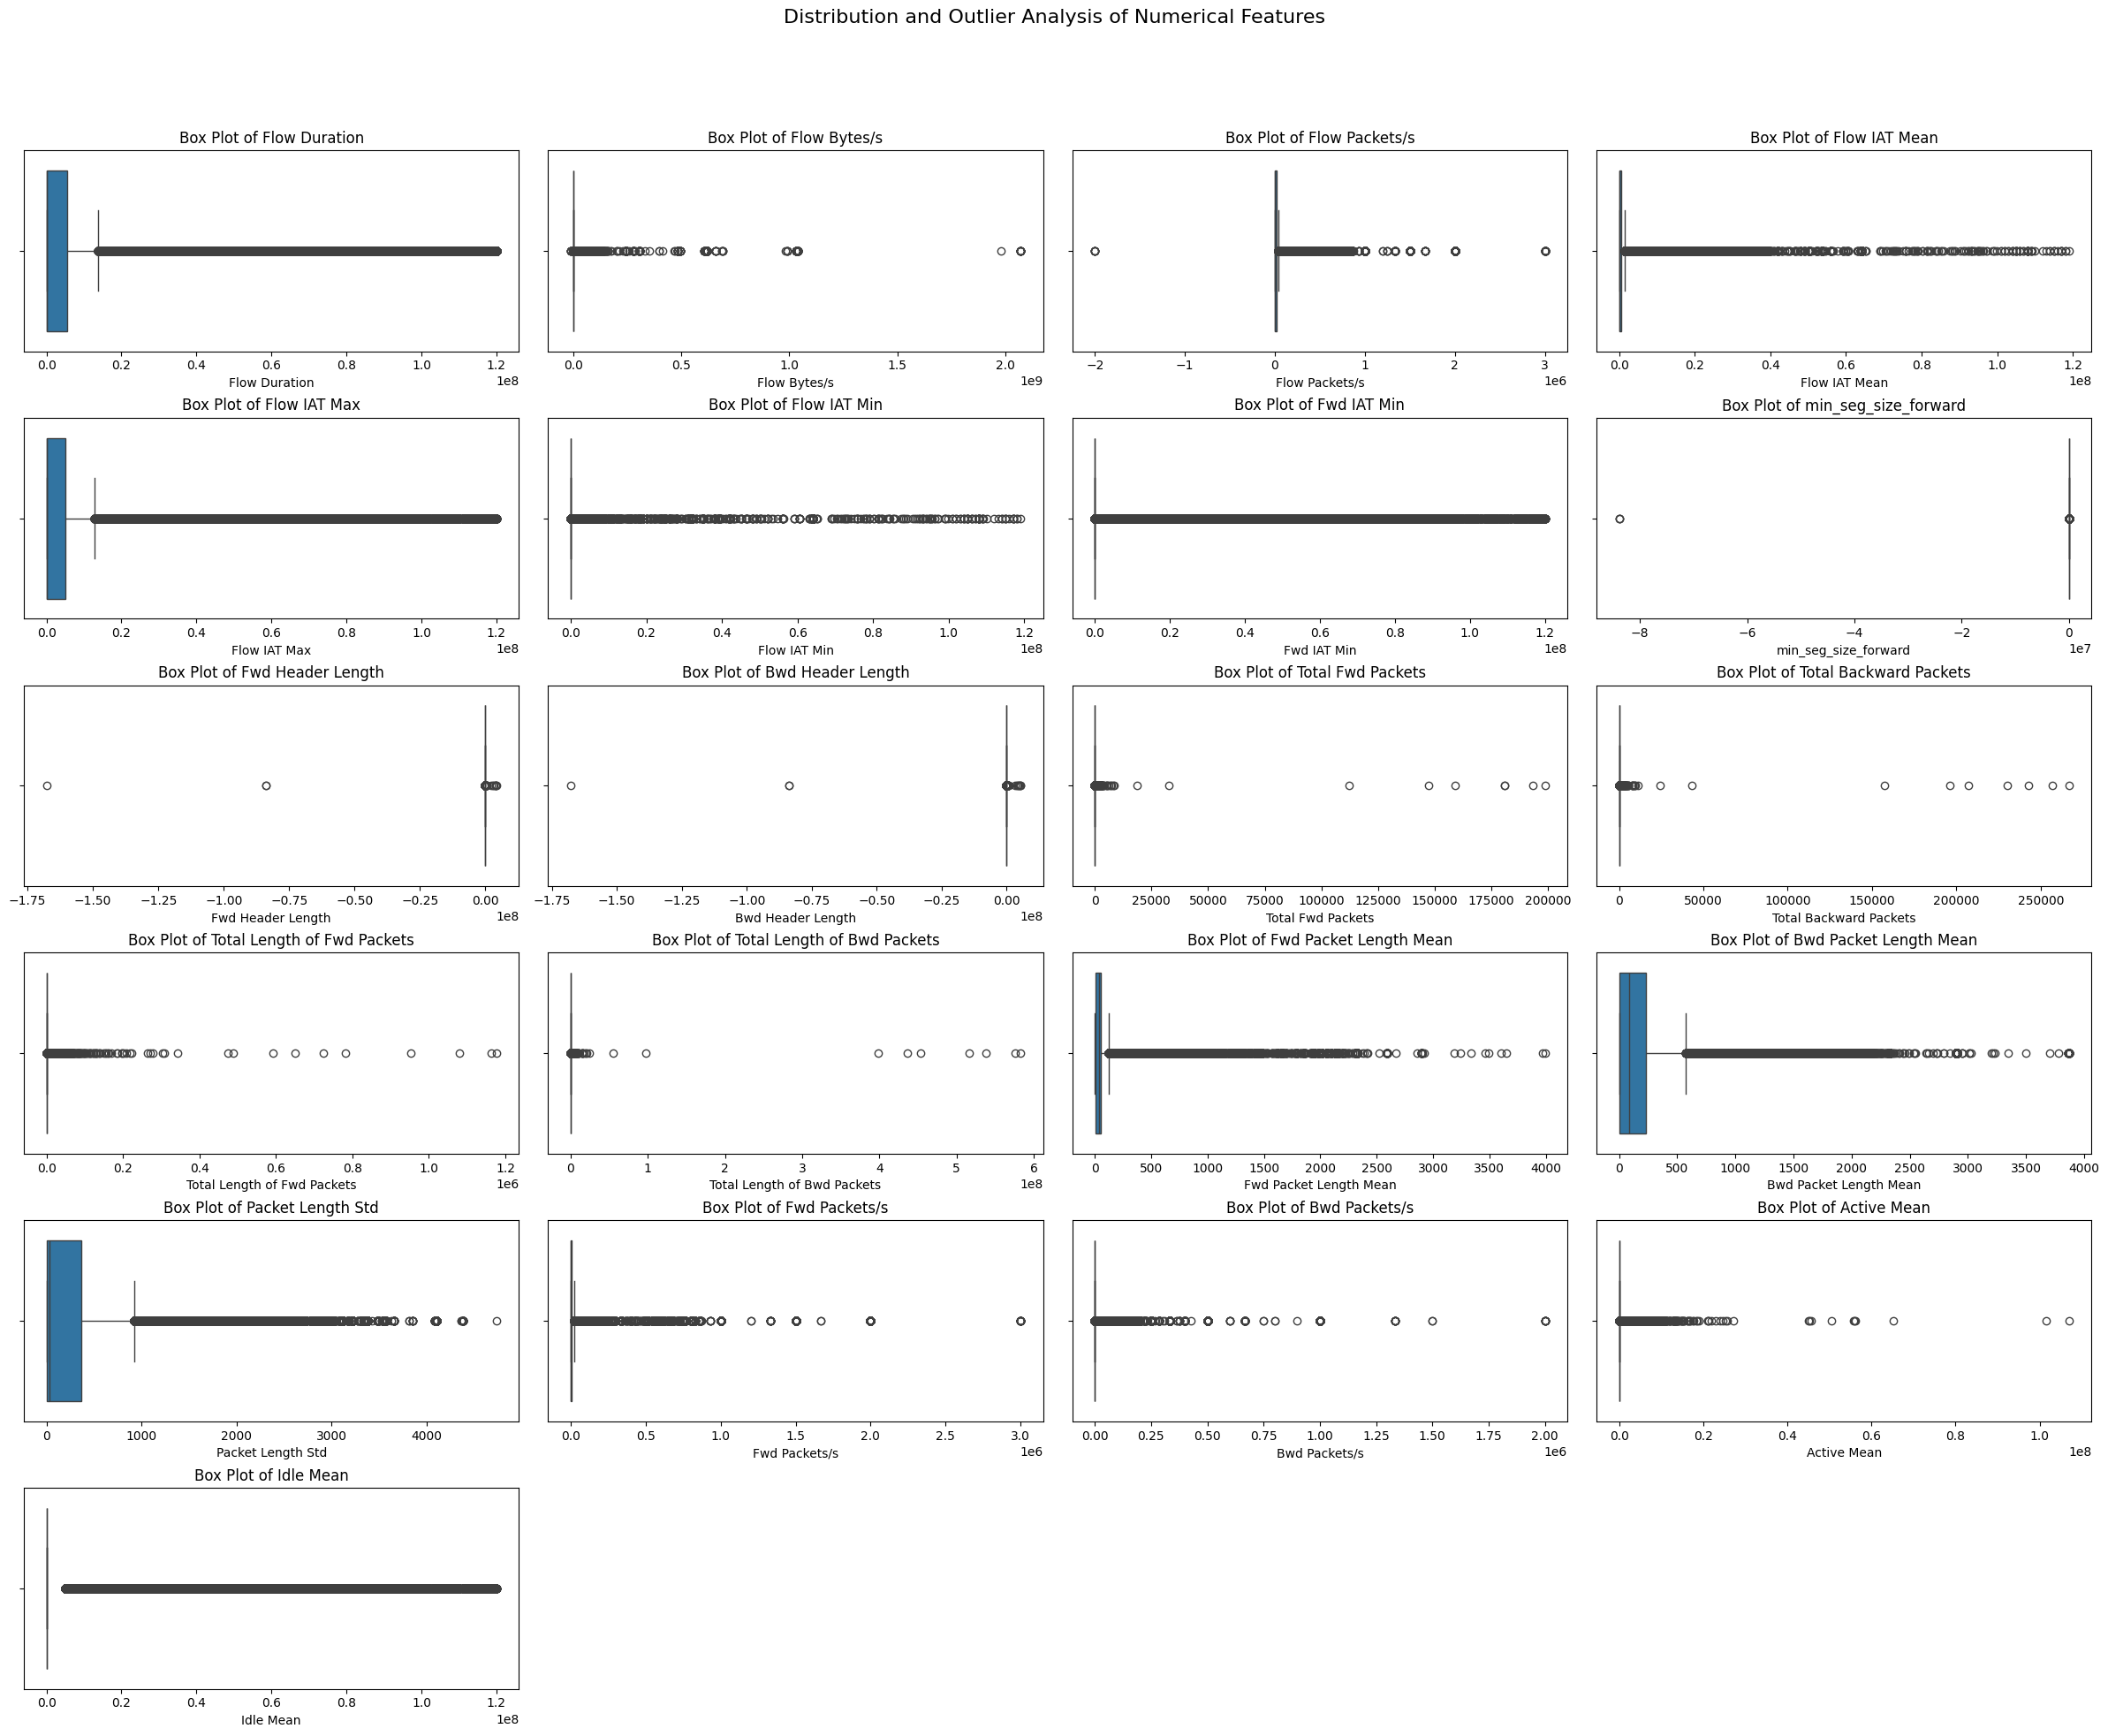

In [ ]:
fig, axes = plt.subplots(6, 4, figsize=(24, 20))

# Flatten the axes so they can be accessed in a loop
axes = axes.flatten()

# Create one box plot in each dashboard section
for index, column in enumerate(columns_to_check):
    sns.boxplot(
        x=df[column],
        ax=axes[index]
    )

    axes[index].set_title(f"Box Plot of {column}")
    axes[index].set_xlabel(column)

# Hide any unused dashboard section
for index in range(len(columns_to_check), len(axes)):
    axes[index].set_visible(False)

# Add a title for the full dashboard
fig.suptitle(
    "Distribution and Outlier Analysis of Numerical Features",
    fontsize=16
)

# Adjust spacing so plots do not overlap
plt.tight_layout()

# Leave space for the dashboard title
plt.subplots_adjust(top=0.90)

plt.show()

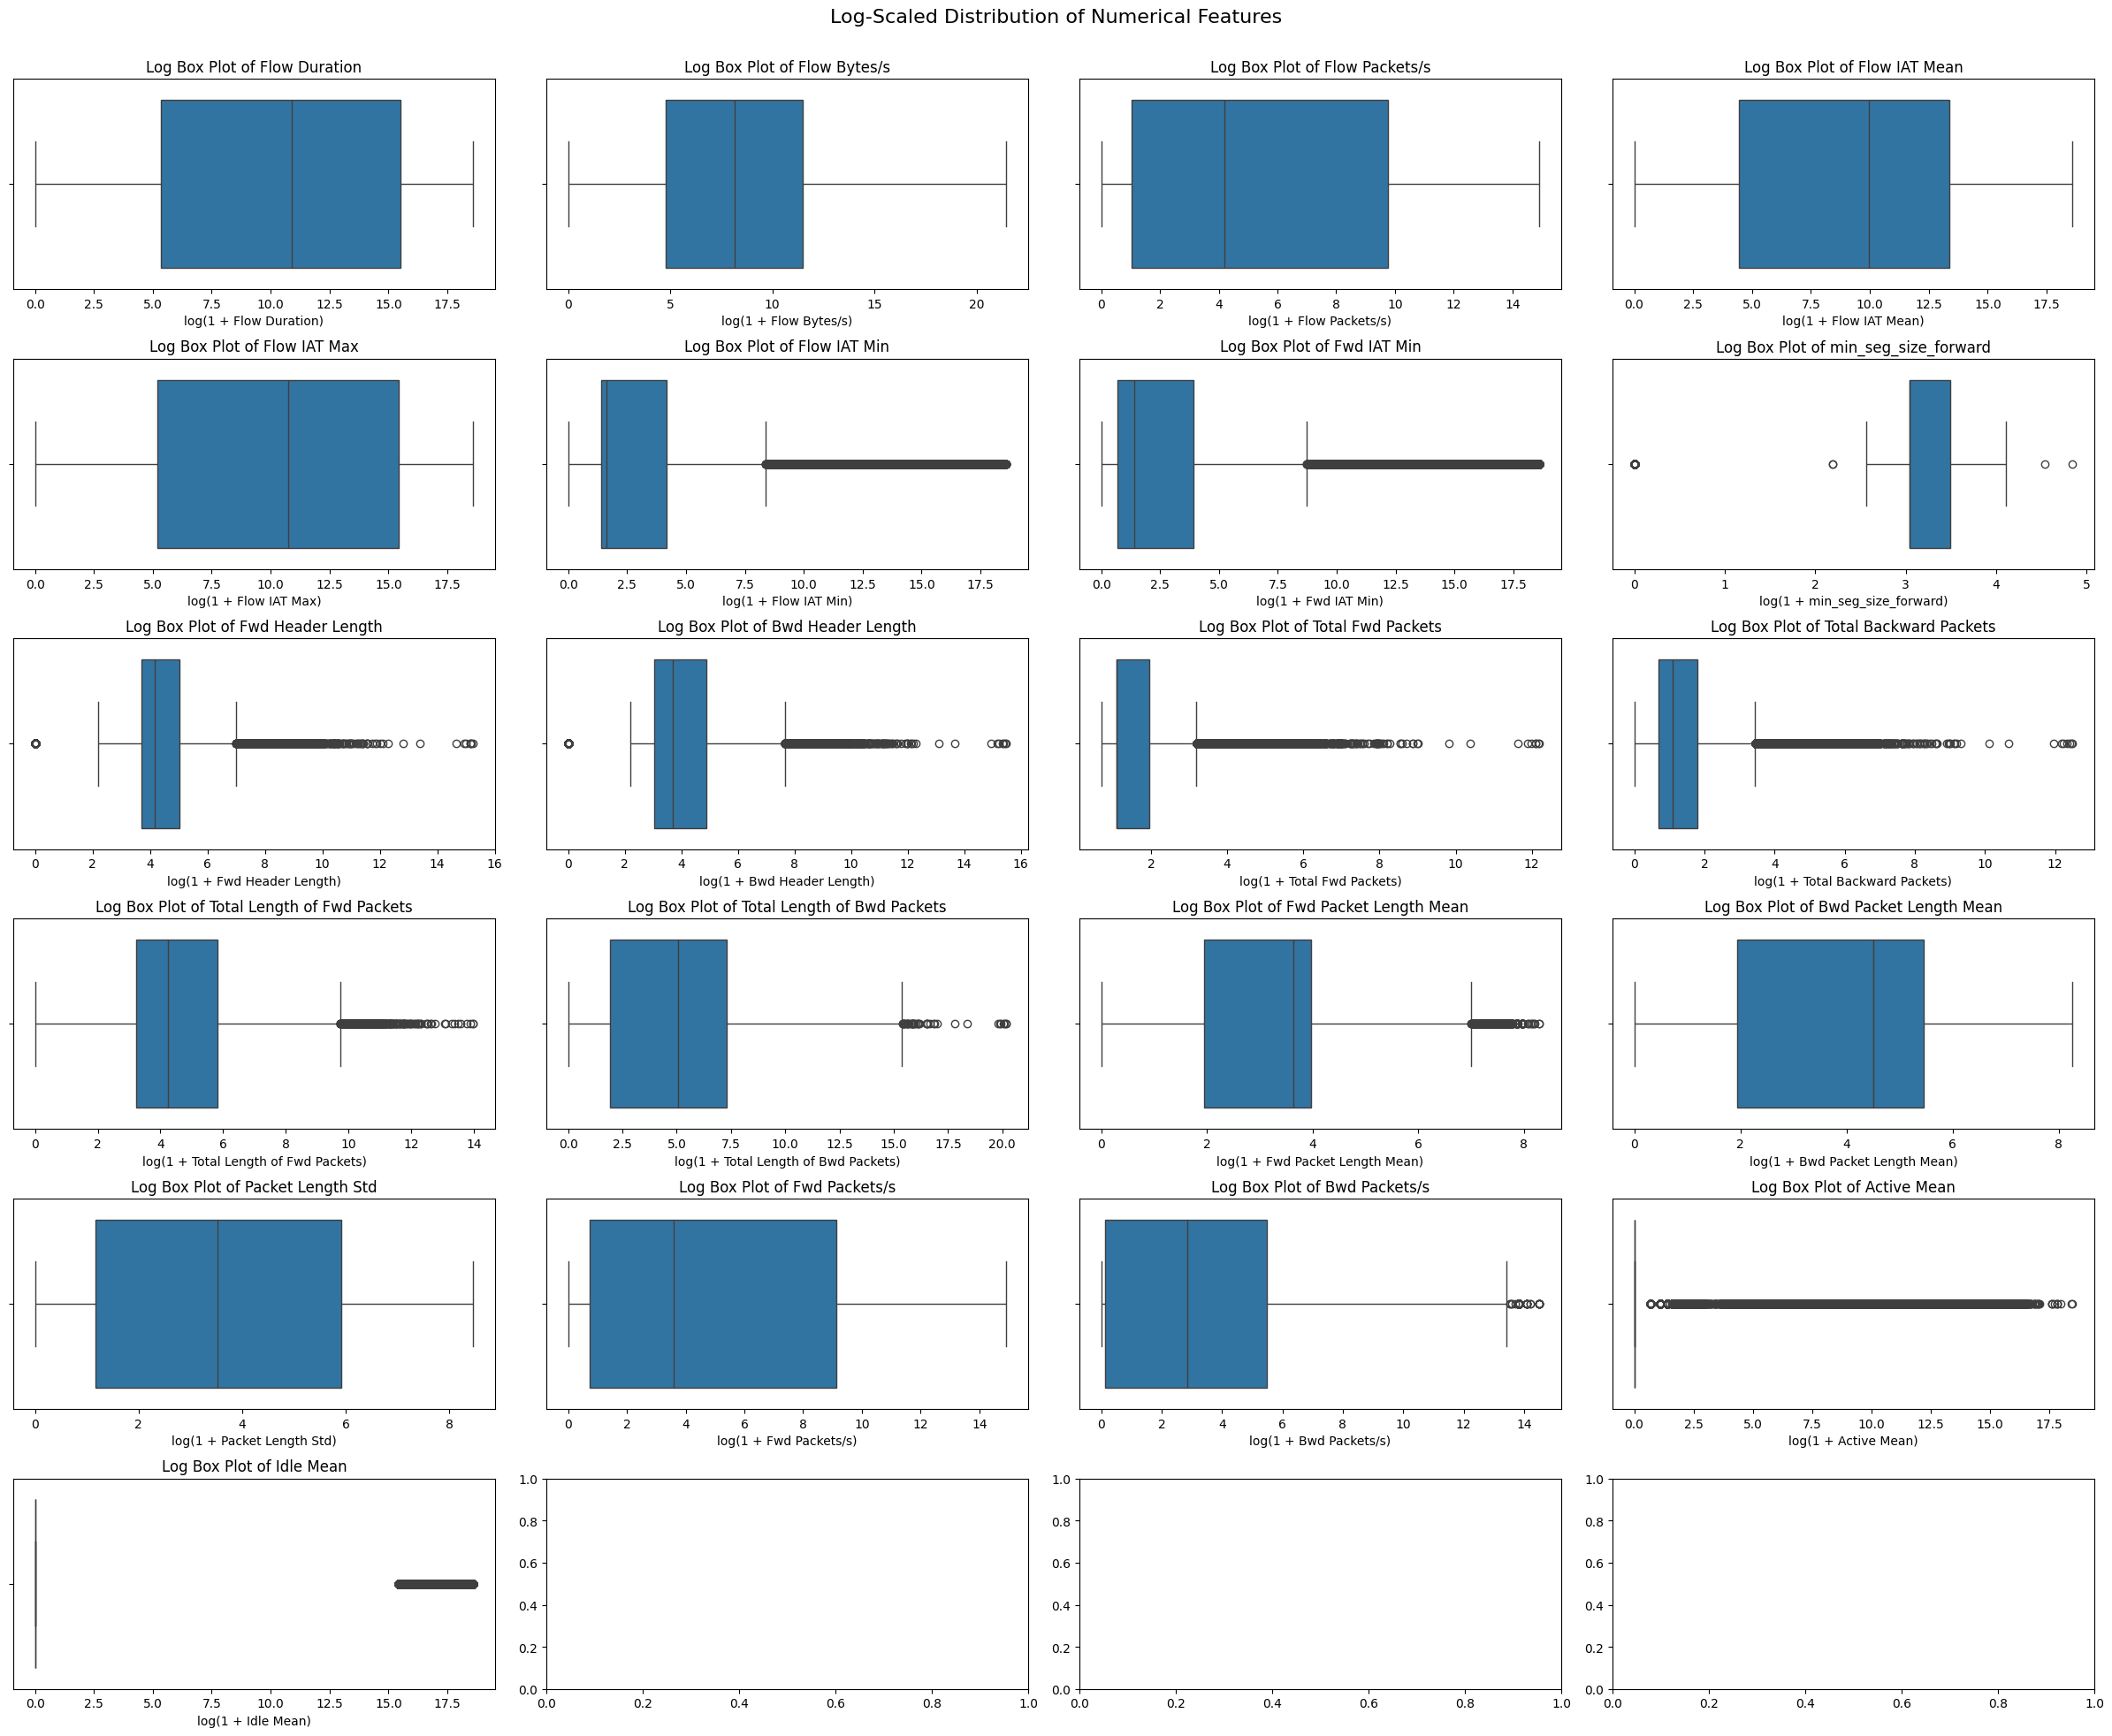

In [ ]:
plot_df = df[columns_to_check].replace([np.inf, -np.inf],np.nan)

# log1p allows zero values
plot_df = np.log1p(plot_df.clip(lower=0))

fig, axes = plt.subplots(6, 4, figsize=(24, 20))

axes = axes.flatten()

for index, column in enumerate(columns_to_check):
    sns.boxplot(
        x=plot_df[column].dropna(),
        ax=axes[index]
    )

    axes[index].set_title(
        f"Log Box Plot of {column}"
    )

    axes[index].set_xlabel(
        f"log(1 + {column})"
    )

fig.suptitle("Log-Scaled Distribution of Numerical Features",fontsize=16)

plt.tight_layout()
plt.subplots_adjust(top=0.94)
plt.show()

In [ ]:
 # count negative values in each selected numerical column
for column in columns_to_check:
    negative_count = (df[column] < 0).sum()
    print(f"{column}: {negative_count} negative values")

# display rows with negative Flow Packets/s values
columns_with_negative_values = df[df["Flow Packets/s"] < 0]

columns_with_negative_values[
    ["Flow Duration",
    "Flow Bytes/s",
    "Flow Packets/s",
    "Flow IAT Mean",
    "Flow IAT Max",
    "Flow IAT Min",
    "Fwd IAT Min",
    "min_seg_size_forward",
    "Fwd Header Length",
    "Bwd Header Length"]
]

Flow Duration: 6 negative values
Flow Bytes/s: 6 negative values
Flow Packets/s: 6 negative values
Flow IAT Mean: 6 negative values
Flow IAT Max: 6 negative values
Flow IAT Min: 355 negative values
Fwd IAT Min: 3 negative values
min_seg_size_forward: 3 negative values
Fwd Header Length: 3 negative values
Bwd Header Length: 3 negative values
Total Fwd Packets: 0 negative values
Total Backward Packets: 0 negative values
Total Length of Fwd Packets: 0 negative values
Total Length of Bwd Packets: 0 negative values
Fwd Packet Length Mean: 0 negative values
Bwd Packet Length Mean: 0 negative values
Packet Length Std: 0 negative values
Fwd Packets/s: 0 negative values
Bwd Packets/s: 0 negative values
Active Mean: 0 negative values
Idle Mean: 0 negative values


,Flow Duration,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Max,Flow IAT Min,Fwd IAT Min,min_seg_size_forward,Fwd Header Length,Bwd Header Length
29920,-1,-12000000.0,-2000000.0,-1.0,-1,-1,0,20,20,20
81485,-1,-12000000.0,-2000000.0,-1.0,-1,-1,0,20,20,20
100241,-1,-12000000.0,-2000000.0,-1.0,-1,-1,0,20,20,20
146882,-1,-12000000.0,-2000000.0,-1.0,-1,-1,0,20,20,20
185777,-1,-12000000.0,-2000000.0,-1.0,-1,-1,0,20,20,20
293351,-1,-12000000.0,-2000000.0,-1.0,-1,-1,0,20,20,20


In [ ]:
# Convert the selected columns into numerical data types
for column in columns_to_check:
    df[column] = pd.to_numeric(
        df[column],
        errors="coerce"
    )

# Convert negative values into missing values
for column in columns_to_check:
    df.loc[df[column] < 0, column] = np.nan

# Fill missing values with the median of each column
for column in columns_to_check:
    df[column] = df[column].fillna(
        df[column].median()
    )

# Confirm that the columns are numeric and contain no invalid values
for column in columns_to_check:
    print(
        f"{column} | "
        f"Type: {df[column].dtype} | "
        f"Negative: {(df[column] < 0).sum()} | "
        f"Missing: {df[column].isnull().sum()}"
    )

Flow Duration | Type: float64 | Negative: 0 | Missing: 0
Flow Bytes/s | Type: float64 | Negative: 0 | Missing: 0
Flow Packets/s | Type: float64 | Negative: 0 | Missing: 0
Flow IAT Mean | Type: float64 | Negative: 0 | Missing: 0
Flow IAT Max | Type: float64 | Negative: 0 | Missing: 0
Flow IAT Min | Type: float64 | Negative: 0 | Missing: 0
Fwd IAT Min | Type: float64 | Negative: 0 | Missing: 0
min_seg_size_forward | Type: float64 | Negative: 0 | Missing: 0
Fwd Header Length | Type: float64 | Negative: 0 | Missing: 0
Bwd Header Length | Type: float64 | Negative: 0 | Missing: 0
Total Fwd Packets | Type: float64 | Negative: 0 | Missing: 0
Total Backward Packets | Type: float64 | Negative: 0 | Missing: 0
Total Length of Fwd Packets | Type: float64 | Negative: 0 | Missing: 0
Total Length of Bwd Packets | Type: float64 | Negative: 0 | Missing: 0
Fwd Packet Length Mean | Type: float64 | Negative: 0 | Missing: 0
Bwd Packet Length Mean | Type: float64 | Negative: 0 | Missing: 0
Packet Length Std 

In [ ]:
# count negative values in each selected numerical column
negative_col = ["Flow Duration",
    "Flow Bytes/s",
    "Flow Packets/s",
    "Flow IAT Mean",
    "Flow IAT Max",
    "Flow IAT Min",
    "Fwd IAT Min",
    "min_seg_size_forward",
    "Fwd Header Length",
    "Bwd Header Length"]

for column in negative_col:
    negative_count = (df[column] < 0).sum()
    print(f"{column}: {negative_count} negative values")

Flow Duration: 0 negative values
Flow Bytes/s: 0 negative values
Flow Packets/s: 0 negative values
Flow IAT Mean: 0 negative values
Flow IAT Max: 0 negative values
Flow IAT Min: 0 negative values
Fwd IAT Min: 0 negative values
min_seg_size_forward: 0 negative values
Fwd Header Length: 0 negative values
Bwd Header Length: 0 negative values


In [ ]:
# count missing values
print("Missing values:")
print(df[columns_to_check].isnull().sum())

# count infinite values
print("\nInfinite values:")
print(
    np.isinf(df[columns_to_check]).sum()
)

Missing values:
Flow Duration                  0
Flow Bytes/s                   0
Flow Packets/s                 0
Flow IAT Mean                  0
Flow IAT Max                   0
Flow IAT Min                   0
Fwd IAT Min                    0
min_seg_size_forward           0
Fwd Header Length              0
Bwd Header Length              0
Total Fwd Packets              0
Total Backward Packets         0
Total Length of Fwd Packets    0
Total Length of Bwd Packets    0
Fwd Packet Length Mean         0
Bwd Packet Length Mean         0
Packet Length Std              0
Fwd Packets/s                  0
Bwd Packets/s                  0
Active Mean                    0
Idle Mean                      0
dtype: int64

Infinite values:
Flow Duration                    0
Flow Bytes/s                     0
Flow Packets/s                 171
Flow IAT Mean                    0
Flow IAT Max                     0
Flow IAT Min                     0
Fwd IAT Min                      0
min_seg_size_fo

In [ ]:
# replace positive and negative infinity with missing values
df["Flow Packets/s"] = df["Flow Packets/s"].replace(
    [np.inf, -np.inf],
    np.nan
)

# calculate the median using valid values
flow_packets_median = df["Flow Packets/s"].median()

# fill the missing values with the median
df["Flow Packets/s"] = df["Flow Packets/s"].fillna(
    flow_packets_median
)

# confirm that no infinite or missing values remain
print(
    "Infinite values remaining:",
    np.isinf(df["Flow Packets/s"]).sum()
)

print("Median used:", flow_packets_median)

Infinite values remaining: 0
Median used: 66.1004065175


In [ ]:
# Count missing values in categorical columns
print(df["Label"].isnull().sum())

0


In [ ]:
# check the class distribution before removal
print("Class distribution before removal:")
print(df["Label"].value_counts())

# classes with too few records for reliable training and testing
classes_to_remove = [
    "Heartbleed",
    "Infiltration",
    "Web Attack - Sql Injection"
]

# remove the selected classes
df = df[
    ~df["Label"].isin(classes_to_remove)
].copy()

# reset the row index
df.reset_index(drop=True, inplace=True)


print("\nClass distribution after removal:")
print(df["Label"].value_counts())
print("\nUpdated dataset shape:")
print(df.shape)

Class distribution before removal:
Label
BENIGN                        283284
DoS Hulk                       26483
DDoS                           19343
DoS GoldenEye                   1505
FTP-Patator                      953
DoS slowloris                    822
DoS Slowhttptest                 781
SSH-Patator                      571
Web Attack - Brute Force         249
Web Attack - XSS                 104
Web Attack - Sql Injection         5
Infiltration                       5
Heartbleed                         2
Name: count, dtype: int64

Class distribution after removal:
Label
BENIGN                      283284
DoS Hulk                     26483
DDoS                         19343
DoS GoldenEye                 1505
FTP-Patator                    953
DoS slowloris                  822
DoS Slowhttptest               781
SSH-Patator                    571
Web Attack - Brute Force       249
Web Attack - XSS               104
Name: count, dtype: int64

Updated dataset shape:
(334095, 66

In [ ]:
from sklearn.preprocessing import LabelEncoder

# convert text labels into numerical values
label_encoder = LabelEncoder()

df["Encoded_Label"] = label_encoder.fit_transform(df["Label"])

# display the mapping between each label and its number
label_mapping = dict(
    zip(
        label_encoder.classes_,
        label_encoder.transform(label_encoder.classes_)
    )
)

# display each label and encoded value
print("Label Encoding Mapping:")

for label, number in label_mapping.items():
    print(f"{label}: {number}")

Label Encoding Mapping:
BENIGN: 0
DDoS: 1
DoS GoldenEye: 2
DoS Hulk: 3
DoS Slowhttptest: 4
DoS slowloris: 5
FTP-Patator: 6
SSH-Patator: 7
Web Attack - Brute Force: 8
Web Attack - XSS: 9


In [ ]:
# Display the target distribution after encoding
print(df["Encoded_Label"].value_counts())

# Display the data types of all columns
print(df.dtypes)

Encoded_Label
0    283284
3     26483
1     19343
2      1505
6       953
5       822
4       781
7       571
8       249
9       104
Name: count, dtype: int64
Destination Port                 int64
Flow Duration                  float64
Total Fwd Packets              float64
Total Backward Packets         float64
Total Length of Fwd Packets    float64
                                ...   
Idle Std                       float64
Idle Max                         int64
Idle Min                         int64
Label                           object
Encoded_Label                    int64
Length: 67, dtype: object


In [ ]:
# will remove both label columns to prevent data leakage
X = df.drop(columns=["Label", "Encoded_Label"])

# encoded label as the prediction target
y = df["Encoded_Label"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (334095, 65)
Target shape: (334095,)


In [ ]:
from sklearn.model_selection import train_test_split

# Split the dataset into 80% training data and 20% testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (267276, 65)
X_test shape: (66819, 65)
y_train shape: (267276,)
y_test shape: (66819,)


In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    min_samples_split=10,
    min_samples_leaf=5,
    max_features="sqrt",
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest model training completed.")

Random Forest model training completed.


In [ ]:
# predict the encoded labels for the test dataset
y_pred = rf_model.predict(X_test)

print("First 10 encoded predictions:")
print(y_pred[:10])

First 10 encoded predictions:
[0 0 0 0 3 0 0 0 0 0]


In [ ]:
# convert predicted numbers back into their original traffic labels
predicted_labels = label_encoder.inverse_transform(
    y_pred.astype(int)
)

print("First 10 predicted traffic labels:")
print(predicted_labels[:10])

First 10 predicted traffic labels:
['BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'DoS Hulk' 'BENIGN' 'BENIGN' 'BENIGN'
 'BENIGN' 'BENIGN']


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# calculating the model's overall accuracy
accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy: {accuracy:.4f}")

# fisplay precision, recall and F1-score for every traffic class
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

#confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(conf_matrix)

Accuracy: 0.9957

Classification Report:
                          precision    recall  f1-score   support

                  BENIGN       1.00      1.00      1.00     56657
                    DDoS       1.00      1.00      1.00      3869
           DoS GoldenEye       0.97      0.98      0.98       301
                DoS Hulk       0.99      1.00      0.99      5297
        DoS Slowhttptest       0.86      0.99      0.92       156
           DoS slowloris       0.99      0.99      0.99       164
             FTP-Patator       0.98      1.00      0.99       190
             SSH-Patator       0.96      0.99      0.97       114
Web Attack - Brute Force       0.35      0.58      0.44        50
        Web Attack - XSS       0.14      0.71      0.23        21

                accuracy                           1.00     66819
               macro avg       0.82      0.92      0.85     66819
            weighted avg       1.00      1.00      1.00     66819


Confusion Matrix:
[[56414     9

## Model Extraction: Save Model for Deployment


In [ ]:
# Save the trained model, label encoder, and feature column list
# so they can be used by the Streamlit app without retraining.
import joblib

joblib.dump(rf_model, "rf_model.pkl")
joblib.dump(label_encoder, "label_encoder.pkl")

feature_columns = X_train.columns.tolist()
joblib.dump(feature_columns, "feature_columns.pkl")

print("Saved: rf_model.pkl, label_encoder.pkl, feature_columns.pkl")
print(f"Number of features: {len(feature_columns)}")

# Download the three files to the computer
from google.colab import files
files.download("rf_model.pkl")
files.download("label_encoder.pkl")
files.download("feature_columns.pkl")

Saved: rf_model.pkl, label_encoder.pkl, feature_columns.pkl
Number of features: 65


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Streamlit App

In [ ]:
# Save the streamlit app
%%writefile app.py
"""
AI-Powered SOC Triage Tool
--------------------------
Emerging AI Trends in Cybersecurity — Assignment 2

Analysts upload a CSV of network flow records (same feature format as
CIC-IDS2017 / CICFlowMeter output). The app runs each flow through a
trained Random Forest model and classifies it as BENIGN or one of the
attack types (DDoS, DoS Hulk, Web Attack - XSS, etc.), then presents a
triage dashboard so an analyst can quickly see what needs attention.
"""

import io

import joblib
import numpy as np
import pandas as pd
import streamlit as st

# ------------------------------------------------------------------
# Page config
# ------------------------------------------------------------------
st.set_page_config(
    page_title="SOC Triage Tool",
    page_icon="🛡️",
    layout="wide",
)

MODEL_PATH = "rf_model.pkl"
ENCODER_PATH = "label_encoder.pkl"
FEATURES_PATH = "feature_columns.pkl"


# ------------------------------------------------------------------
# Cached model loading — runs once, not on every interaction
# ------------------------------------------------------------------
@st.cache_resource
def load_artifacts():
    model = joblib.load(MODEL_PATH)
    label_encoder = joblib.load(ENCODER_PATH)
    feature_columns = joblib.load(FEATURES_PATH)
    return model, label_encoder, feature_columns


def preprocess(df: pd.DataFrame, feature_columns: list[str]) -> tuple[pd.DataFrame, list[str], list[str]]:
    """Clean an uploaded CSV and align it to the training feature schema.

    Returns the aligned feature dataframe plus lists of any columns
    that were missing (filled with 0) or ignored (extra/unused), so
    the analyst can be warned about schema mismatches.
    """
    df = df.copy()
    df.columns = df.columns.str.strip()

    # Drop label columns if the analyst uploaded an already-labelled file
    df = df.drop(columns=[c for c in ["Label", "Encoded_Label"] if c in df.columns])

    # Same cleaning steps used in training: inf -> NaN -> median fill
    df = df.replace([np.inf, -np.inf], np.nan)

    missing_cols = [c for c in feature_columns if c not in df.columns]
    extra_cols = [c for c in df.columns if c not in feature_columns]

    for col in missing_cols:
        df[col] = 0

    df = df[feature_columns]  # exact order the model expects

    for col in df.columns:
        if df[col].isna().any():
            df[col] = df[col].fillna(df[col].median() if df[col].notna().any() else 0)

    return df, missing_cols, extra_cols


# ------------------------------------------------------------------
# Sidebar
# ------------------------------------------------------------------
with st.sidebar:
    st.title("🛡️ SOC Triage Tool")
    st.markdown(
        "AI-powered network intrusion classifier trained on the "
        "**CIC-IDS2017** dataset using a **Random Forest** model."
    )
    st.markdown("---")
    st.markdown("**How to use**")
    st.markdown(
        "1. Upload a CSV of network flow records\n"
        "2. The model classifies each flow\n"
        "3. Review the triage summary below\n"
        "4. Download the annotated results"
    )
    st.markdown("---")
    st.caption(
        "Built for Emerging AI Trends in Cybersecurity: Assignment 2. "
        "This is a decision-support tool, not a replacement for analyst judgement."
    )

# ------------------------------------------------------------------
# Load model
# ------------------------------------------------------------------
try:
    model, label_encoder, feature_columns = load_artifacts()
except FileNotFoundError:
    st.error(
        "Model files not found. Make sure `rf_model.pkl`, `label_encoder.pkl`, "
        "and `feature_columns.pkl` are in the same folder as `app.py` "
        "(see `add_to_notebook_model_export.py` for how to generate them)."
    )
    st.stop()

st.title("Network Traffic Triage Dashboard")
st.write(
    "Upload a CSV of network flow records (CICFlowMeter-style columns, "
    "same format as the CIC-IDS2017 dataset) to classify traffic as "
    "benign or malicious."
)

uploaded_file = st.file_uploader("Upload network flow CSV", type=["csv"])

if uploaded_file is None:
    st.info("Waiting for a CSV upload to begin analysis.")
    st.stop()

# ------------------------------------------------------------------
# Read + preprocess
# ------------------------------------------------------------------
try:
    raw_df = pd.read_csv(uploaded_file)
except Exception as e:
    st.error(f"Could not read the uploaded file: {e}")
    st.stop()

with st.spinner("Preprocessing and classifying network flows..."):
    X, missing_cols, extra_cols = preprocess(raw_df, feature_columns)
    y_pred_encoded = model.predict(X)
    y_pred_labels = label_encoder.inverse_transform(y_pred_encoded.astype(int))

    # Confidence = probability of the predicted class
    if hasattr(model, "predict_proba"):
        proba = model.predict_proba(X)
        confidence = proba.max(axis=1)
    else:
        confidence = np.full(len(X), np.nan)

results_df = raw_df.copy()
results_df["Predicted_Label"] = y_pred_labels
results_df["Confidence"] = confidence

if missing_cols:
    st.warning(
        f"{len(missing_cols)} expected feature column(s) were missing from your "
        f"upload and were filled with 0 (e.g. {missing_cols[:5]}...). "
        "Predictions on this data may be less reliable."
    )
if extra_cols:
    st.caption(f"{len(extra_cols)} extra column(s) in your upload were ignored (not used by the model).")

# ------------------------------------------------------------------
# Triage summary
# ------------------------------------------------------------------
total_flows = len(results_df)
benign_count = int((results_df["Predicted_Label"] == "BENIGN").sum())
malicious_count = total_flows - benign_count
malicious_pct = (malicious_count / total_flows * 100) if total_flows else 0

col1, col2, col3, col4 = st.columns(4)
col1.metric("Total Flows Analyzed", f"{total_flows:,}")
col2.metric("Benign", f"{benign_count:,}")
col3.metric("Flagged as Malicious", f"{malicious_count:,}")
col4.metric("Malicious Rate", f"{malicious_pct:.2f}%")

if malicious_count > 0:
    st.error(f"⚠️ {malicious_count} flow(s) flagged as potentially malicious — review below.")
else:
    st.success("✅ No malicious traffic detected in this batch.")

st.markdown("---")

# ------------------------------------------------------------------
# Breakdown chart
# ------------------------------------------------------------------
st.subheader("Traffic Type Breakdown")
label_counts = results_df["Predicted_Label"].value_counts()
st.bar_chart(label_counts)

# ------------------------------------------------------------------
# Detailed table with filtering
# ------------------------------------------------------------------
st.subheader("Flow-Level Results")

view_option = st.radio(
    "Show:",
    ["All flows", "Malicious only"],
    horizontal=True,
)

display_df = results_df if view_option == "All flows" else results_df[results_df["Predicted_Label"] != "BENIGN"]

display_cols = ["Predicted_Label", "Confidence"] + [c for c in raw_df.columns if c not in ("Label", "Encoded_Label")]
st.dataframe(display_df[display_cols], use_container_width=True, height=400)

# ------------------------------------------------------------------
# Download
# ------------------------------------------------------------------
csv_buffer = io.StringIO()
results_df.to_csv(csv_buffer, index=False)
st.download_button(
    "Download annotated results as CSV",
    data=csv_buffer.getvalue(),
    file_name="soc_triage_results.csv",
    mime="text/csv",
)

Overwriting app.py


## requirements.txt

In [ ]:
# Save requirements.txt
%%writefile requirements.txt
streamlit
pandas
numpy
joblib

Overwriting requirements.txt


In [ ]:
# Downloading app.py and requirements.txt
files.download("app.py")
files.download("requirements.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Create a small sample CSV to test the Streamlit app with
test_sample = X_test.sample(n=200, random_state=1)
test_sample["Label"] = label_encoder.inverse_transform(y_test.loc[test_sample.index])
test_sample.to_csv("streamlit_test_sample.csv", index=False)

from google.colab import files
files.download("streamlit_test_sample.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Remove the quotes when testing match rate
'''
test = pd.read_csv("streamlit_test_sample.csv")
results = pd.read_csv("soc_triage_results.csv")  # downloaded from the app
match_rate = (test["Label"] == results["Predicted_Label"]).mean()
print(f"Match rate: {match_rate:.2%}")'''

'\ntest = pd.read_csv("streamlit_test_sample.csv")\nresults = pd.read_csv("soc_triage_results.csv")  # downloaded from the app\nmatch_rate = (test["Label"] == results["Predicted_Label"]).mean()\nprint(f"Match rate: {match_rate:.2%}")'